# Curve factor forecasting

Research question: Can either challenger improve a simple rate forecast or its decision?

Inputs: frozen Treasury 2024–2025 CSVs. Rates are decimals, prices per 100 face. Release 1.0.0. No live signal.

In [1]:
import sys,json
from pathlib import Path
from datetime import date
import numpy as np
R=Path.cwd()
if R.name=='notebooks':R=R.parent
sys.path.insert(0,str(R/'src'));sys.path.insert(0,str(R/'scripts'))
from curve_lab.data import load_history
from curve_lab.bonds import Bond
from curve_lab.curves import bootstrap,par_rate,TENORS,KEYS,fit_nelson_siegel
from curve_lab.risk import bond_risk,hedge,carry_bridge
from curve_lab.forecast import predict,evaluate
from review_display import table,figure
if 'display_bundle' not in globals():
    from IPython.display import display
    def display_bundle(bundle):display(bundle,raw=True)
D=json.loads((R/'artifacts/release/research.json').read_text());rows,receipts=load_history(R)
print('Run',D['run_id'],'| source through',D['as_of'],'| hypothetical bond valuations')


Run p4-662f58a64e8e | source through 2025-12-31 | hypothetical bond valuations


## Inspect every candidate error

Model,RMSE bp,MAE bp,Origins
no_change,9.3972544,7.1428571,49
pca_ar,10.682569,8.0113555,49
ridge_change,9.4132736,7.1828001,49


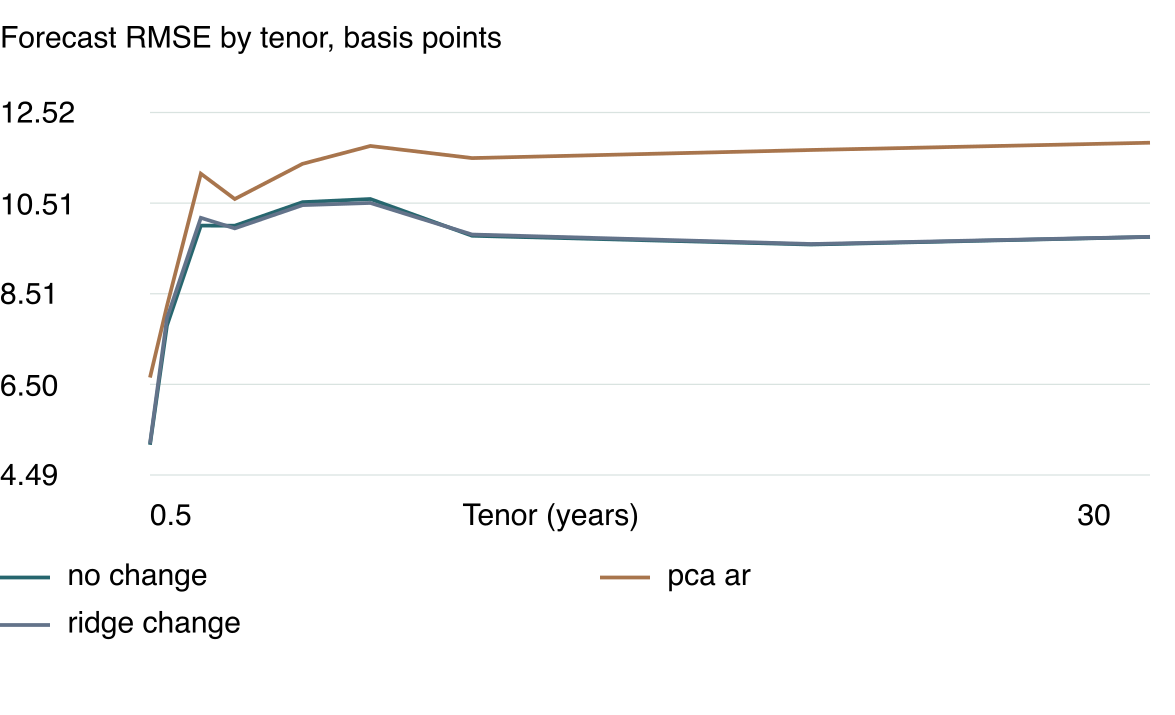

In [2]:
display_bundle(table(['Model','RMSE bp','MAE bp','Origins'],[[n,m['rmse_bp'],m['mae_bp'],m['origins']] for n,m in D['forecast']['metrics'].items()]));display_bundle(figure('forecast'))

## Rebuild the first forecast from eligible history

In [3]:
r=D['forecast']['origins'][0];y=np.array([x['par'] for x in rows]);pred,fit=predict(y[:r['origin_index']+1]);assert fit['max_target_index']==r['origin_index'];display_bundle(table(['Model','Reconstruction max absolute error'],[[n,float(np.max(abs(pred[n]-r['predictions'][n])))] for n in pred]));assert max(np.max(abs(pred[n]-r['predictions'][n])) for n in pred)<1e-12

Model,Reconstruction max absolute error
no_change,0
pca_ar,0
ridge_change,0


## Inspect costed hypothetical decision value

Policy,Terminal wealth,Mean long weight,Worst period
fixed_mix,1.0477794,0.5,-0.010029202
no_change,1.0477794,0.5,-0.010029202
pca_ar,1.0370101,0.24489796,-0.010029202
ridge_change,1.0473771,0.2755102,-0.010029202


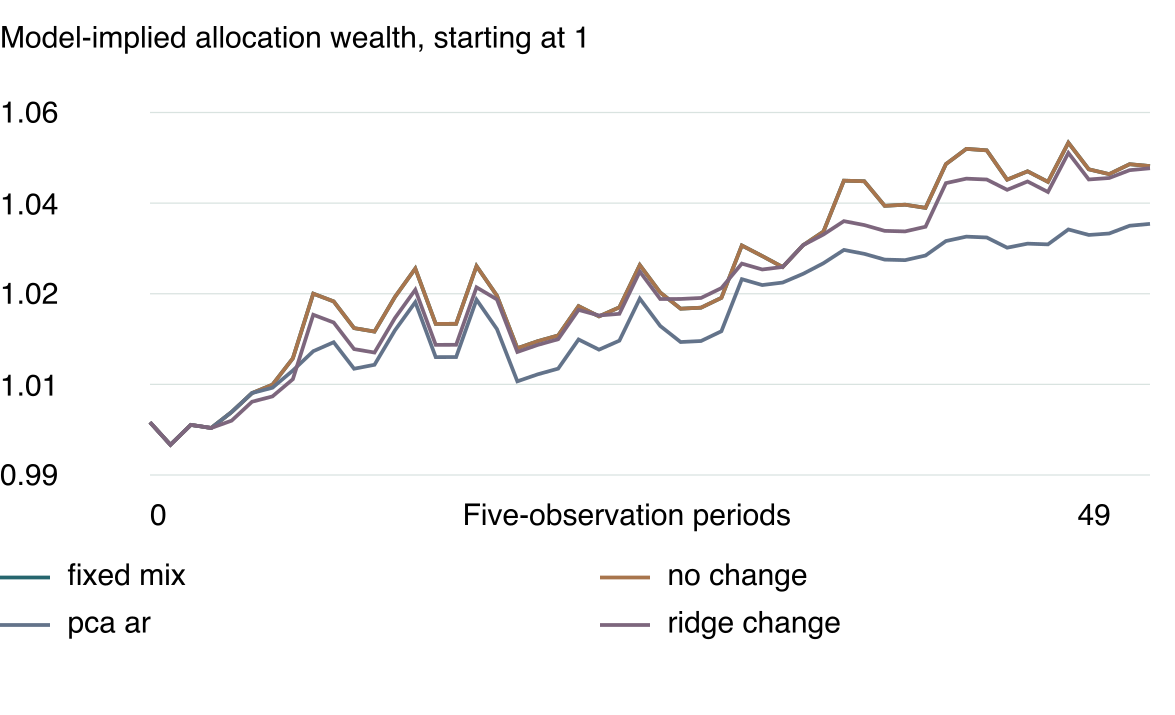

In [4]:
display_bundle(table(['Policy','Terminal wealth','Mean long weight','Worst period'],[[n,a['terminal_wealth'],a['mean_long_weight'],a['worst_period']] for n,a in D['forecast']['allocation'].items()]));display_bundle(figure('allocation'));assert all(x['starting_duration']<=6+1e-9 for a in D['forecast']['allocation'].values() for x in a['periods'])

## Interpretation

No-change has the lowest aggregate forecast RMSE. The allocation illustration is model-implied, not a traded bond return series. All policies remain visible and none is promoted from this short retrospective sample.

Canonical evidence: `artifacts/release/research.json`; source receipts: `data/manifests/sources.json`.